In [1]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 1. Интервалы из ошибок модели: аналитические, эмпирические, бутстреп

**Сквозной вопрос блока:** модель говорит 95% — а сколько на самом деле?

В этом ноутбуке:
- кратко повторяем метрики интервалов (coverage, width, Winkler, pinball) —
  [подробный разбор был в неделе 2](../../week_2/part_1/03.%20%D0%98%D0%BD%D1%82%D0%B5%D1%80%D0%B2%D0%B0%D0%BB%D1%8B%20%D0%BF%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F%20%D0%B8%20%D0%BE%D1%86%D0%B5%D0%BD%D0%BA%D0%B0%20%D0%B8%D1%85%20%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0.ipynb);
- смотрим на аналитические интервалы statsforecast **на бэктесте**, а не на одном тесте;
- строим интервалы из ошибок кросс-валидации: одна σ против σ по горизонту и эмпирических квантилей;
- разбираем, чем отличаются варианты бутстрепа (i.i.d., блочный, циркулярный, стационарный, остатков)
  и где какой уместен;
- бутстреп остатков через `simulate` и бэггинг рядов через sktime;
- итог: покрытие — не единственная метрика, и «95%» надо проверять на многих окнах.

In [2]:
import warnings
warnings.filterwarnings('ignore')
warnings.showwarning = lambda *args, **kwargs: None # sktime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoARIMA, SeasonalNaive

from utilsforecast.losses import coverage, winkler_score
from utilsforecast.plotting import plot_series

from sktime.forecasting.compose import BaggingForecaster
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.arima import ARIMA
from sktime.transformations.bootstrap import STLBootstrapTransformer

sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 4)

## 0. Данные: и последняя точка после агрегации

Часовые данные AEP агрегируем до дневного потребления (МВт·ч). Ряд один — зато потом
получим сотни скользящих окон, и на них покрытие можно оценить надёжно.

**Ловушка агрегации.** Если просто сделать `resample('D').sum()`, последние сутки в данных
почти наверняка окажутся неполными: файл обрывается не на границе дня. Сумма за такой день
в разы меньше настоящей, и она попадает в конец ряда — ровно туда, куда модель смотрит
внимательнее всего. На графике это выглядит как «обвал спроса», а на деле это артефакт.

Поэтому сначала считаем число часов в сутках и отбрасываем сутки, где их заведомо мало.

In [3]:
df_hour = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/AEP_hourly.csv', parse_dates=['Datetime'])
df_hour.columns = ['ds', 'y']

by_day = df_hour.resample('D', on='ds')
hours_per_day, day_total = by_day.size(), by_day.sum()

print("Часов в сутках:")
print(hours_per_day.value_counts().sort_index().to_string())
print("\nСутки с аномальным числом часов:")
print(hours_per_day[hours_per_day != 24].tail(6).to_string())

Часов в сутках:
1        1
23      28
24    5022
25       4

Сутки с аномальным числом часов:
ds
2016-03-13    23
2016-11-06    25
2017-03-12    23
2017-11-05    25
2018-03-11    23
2018-08-03     1


In [4]:
# Отбрасываем сутки, где часов меньше 23 (обрыв файла). 23/25 часов — это переход на летнее
# время, такие сутки настоящие и остаются.
MIN_HOURS = 23
keep = hours_per_day >= MIN_HOURS

df = day_total[keep.values].reset_index()
df['unique_id'] = 'AEP'

gaps = (df['ds'].diff().dropna() != pd.Timedelta('1D')).sum()
print(f"Дневных наблюдений: {len(df)}, период {df['ds'].min().date()} — {df['ds'].max().date()}")
print(f"Пропусков в календаре: {gaps}")
print(f"Отброшено суток: {(~keep).sum()}")

Дневных наблюдений: 5054, период 2004-10-01 — 2018-08-02
Пропусков в календаре: 0
Отброшено суток: 1


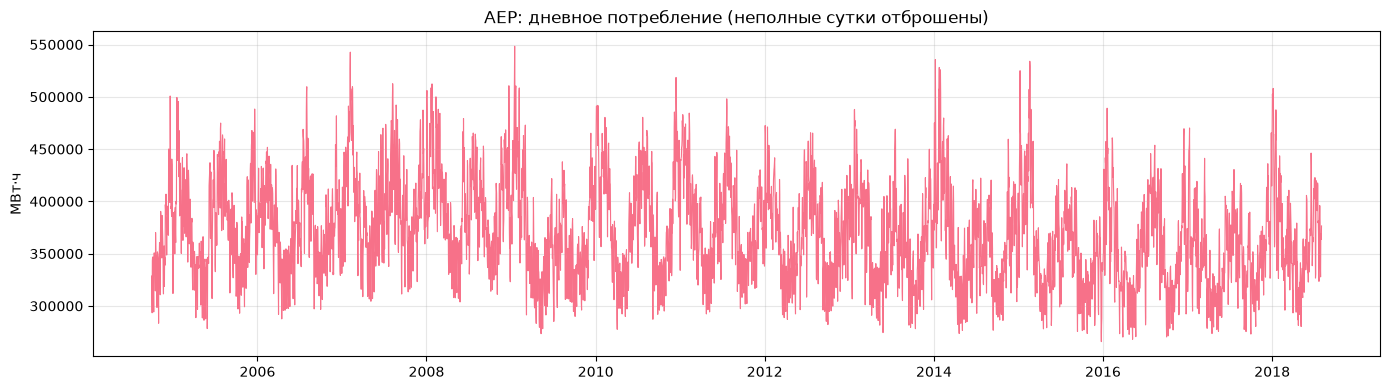

In [5]:
plt.figure(figsize=(14, 4))
plt.plot(df['ds'], df['y'], linewidth=0.8)
plt.title('AEP: дневное потребление (неполные сутки отброшены)')
plt.ylabel('МВт·ч')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Сравните с наивной агрегацией: без фильтра последняя точка была бы в 25 раз ниже нормы —
и любой бэктест, где она попала в тест, показал бы катастрофическую ошибку модели на пустом месте.

### Метрики интервалов (краткое повторение)

- **Coverage** — доля точек внутри интервала; для номинала 95% ожидаем ≈0.95.
- **Width** — средняя ширина; уже интервал при том же покрытии — лучше.
- **Winkler score** — ширина + штраф $\frac{2}{\alpha}$ за каждый промах. Меньше — лучше.
- **Pinball loss** — для отдельного квантиля $\tau$; подробно разбирали в неделе 2.

**Калибровка vs резкость:** покрытие близко к номиналу — калибровка; интервал при этом узкий — резкость.
Покрытие 1.000 при вдвое более широком интервале — это не успех, а перестраховка.

**Почему одно окно ничего не доказывает:** на $H=14$ разница в одну точку — это 7% покрытия.
Нужны десятки окон, поэтому дальше работаем только с бэктестом.

In [6]:
def interval_metrics(backtest, models, level=95):
    """Метрики интервалов по окнам бэктеста (формат statsforecast).

    backtest — вывод `cross_validation`, в нём есть `cutoff`, `y` и колонки
    `{model}`, `{model}-lo-{level}`, `{model}-hi-{level}`.

    Покрытие и Winkler считает `utilsforecast` — по каждому окну отдельно;
    ширина и MAE досчитываются из тех же колонок. Возвращает таблицу: строка — модель.
    """
    rows = []
    for model in models:
        lo, hi = f'{model}-lo-{level}', f'{model}-hi-{level}'
        per_window = pd.DataFrame({
            'coverage': coverage(backtest, models=[model], level=level).set_index('cutoff')[model],
            'width': (backtest[hi] - backtest[lo]).groupby(backtest['cutoff']).mean(),
            'winkler': winkler_score(backtest, models=[model], level=level).set_index('cutoff')[model],
        })
        rows.append(pd.Series({
            'coverage': per_window['coverage'].mean(),
            'coverage_sd': per_window['coverage'].std(),
            'coverage_min': per_window['coverage'].min(),
            'width': per_window['width'].mean(),
            'winkler': per_window['winkler'].mean(),
            'MAE': (backtest['y'] - backtest[model]).abs().mean(),
        }, name=model))
    out = pd.DataFrame(rows)
    out['width/MAE'] = out['width'] / out['MAE']
    return out


print("Хелпер interval_metrics готов: метрики считаются по окнам бэктеста, а не по одному тесту.")

Хелпер interval_metrics готов: метрики считаются по окнам бэктеста, а не по одному тесту.


## 1. Отправная точка: аналитические интервалы statsforecast

AutoETS/AutoARIMA строят интервал из предположений: модель верна, остатки нормальны
и гомоскедастичны, параметры известны точно. Формула — та же, что выводили в неделе 2:
$\hat y_{n+h} \pm z_{1-\alpha/2}\,\hat\sigma_h$, где $\hat\sigma_h$ растёт с горизонтом.

Проверять это надо на бэктесте. `StatsForecast.cross_validation` умеет сразу возвращать
интервалы — не нужно руками двигать окно и складывать остатки по фолдам.

In [7]:
SPLIT = 0.8
H = 14        # горизонт прогноза
N_WINDOWS = 120

split_point = int(len(df) * SPLIT)
train = df.iloc[:split_point].reset_index(drop=True)
test = df.iloc[split_point:].reset_index(drop=True)

sf = StatsForecast(
    models=[
        AutoETS(season_length=7, alias='ETS'),
        AutoARIMA(season_length=7, alias='ARIMA'),
        SeasonalNaive(season_length=7, alias='SNaive'),
    ],
    freq='D',
    n_jobs=1,
)

**`refit=False`** — модель обучается один раз на всём train и дальше только «продвигается»
вперёд по окнам. Это дешево и честно, если ряд стационарен. `refit=True` переобучает
модель на каждом окне: дороже в ~20 раз, но корректно при дрейфе. Дальше используем `False`
и держим в голове эту разницу.

In [8]:
backtest = sf.cross_validation(
    df=train[['unique_id', 'ds', 'y']],
    h=H,
    n_windows=N_WINDOWS,
    level=[95],
    refit=False,
)

print(f"Окон: {backtest['cutoff'].nunique()}, строк: {len(backtest)}")
print(backtest[['unique_id', 'ds', 'cutoff', 'y', 'ETS', 'ETS-lo-95', 'ETS-hi-95']].head(3).to_string(index=False))

Окон: 120, строк: 1680
unique_id         ds     cutoff        y           ETS     ETS-lo-95     ETS-hi-95
      AEP 2015-06-16 2015-06-15 410301.0 422083.061740 383231.963741 460934.159739
      AEP 2015-06-17 2015-06-15 376219.0 420702.488747 365821.582252 475583.395243
      AEP 2015-06-18 2015-06-15 400484.0 420529.077955 353324.171343 487733.984567


In [9]:
# Горизонт внутри окна — пригодится дальше для σ(h) и квантилей по горизонтам.
backtest = backtest.sort_values(['cutoff', 'ds']).reset_index(drop=True)
backtest['h'] = backtest.groupby('cutoff').cumcount() + 1

analytic = interval_metrics(backtest, ['ETS', 'ARIMA', 'SNaive'])
analytic.round(3)

,coverage,coverage_sd,coverage_min,width,winkler,MAE,width/MAE
ETS,0.985,0.057,0.643,172835.273,177108.675,25744.113,6.714
ARIMA,0.976,0.053,0.714,135672.671,141498.268,23806.658,5.699
SNaive,0.983,0.038,0.857,180975.610,185336.679,28821.786,6.279


**Что видно.** Покрытие близко к номиналу или выше него, но интервалы при этом очень широкие:
ширина в ~6–7 раз больше MAE. Для нормального интервала при 95% ожидается ширина около
$2\cdot1.96\sigma \approx 3.9\sigma$, а $\mathrm{MAE}\approx0.8\sigma$, то есть ширина/MAE ≈ 4.9.
Всё, что заметно выше, — перестраховка.

Отсюда важный вывод, который расходится с ходовой формулировкой «аналитические интервалы
всегда занижены»: **на этих данных они не занижены, а раздуты**. Но правило «проверяй покрытие
на бэктесте» от этого не меняется — просто бороться надо с другой болезнью.

In [10]:
# Покрытие рвётся не равномерно: на коротких горизонтах оно около номинала,
# на длинных — 1.0, то есть интервал там заведомо лишний.
backtest['inside_analytic'] = (
    (backtest['y'] >= backtest['ETS-lo-95']) & (backtest['y'] <= backtest['ETS-hi-95'])
)

by_h = pd.DataFrame({
    'coverage': backtest.groupby('h')['inside_analytic'].mean(),
    'width': (backtest['ETS-hi-95'] - backtest['ETS-lo-95']).groupby(backtest['h']).mean(),
    'MAE': (backtest['y'] - backtest['ETS']).abs().groupby(backtest['h']).mean(),
})
by_h['width/MAE'] = by_h['width'] / by_h['MAE']
by_h.round(3)

,coverage,width,MAE,width/MAE
h,,,,
1,0.967,65787.796,12149.307,5.415
2,0.975,93117.016,18859.354,4.937
3,0.958,114141.895,21588.736,5.287
4,0.950,131895.139,24384.125,5.409
5,0.975,147543.807,25195.199,5.856
6,0.983,161707.460,25487.444,6.345
7,0.992,174770.149,26114.324,6.693
8,0.992,186948.789,27156.309,6.884
9,1.000,198399.078,28236.222,7.026


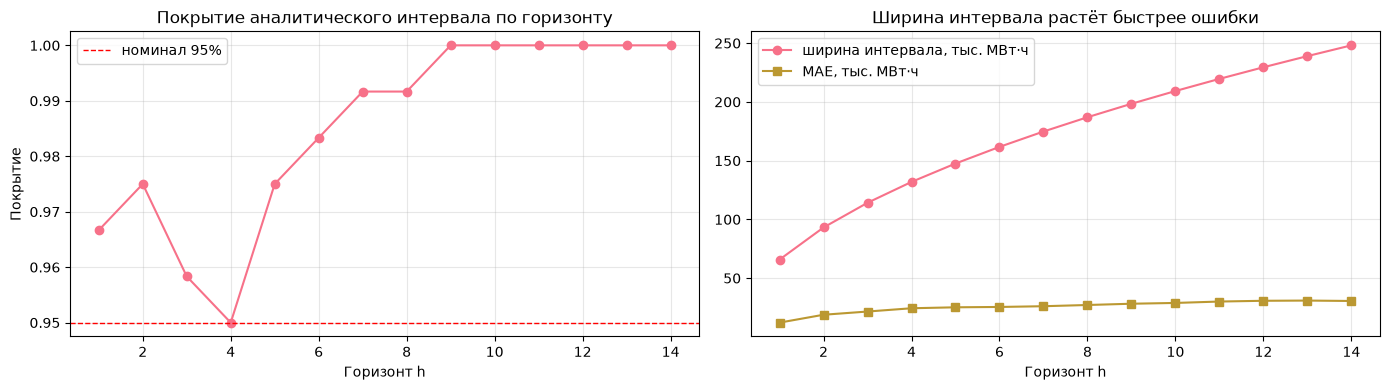

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(by_h.index, by_h['coverage'], 'o-')
axes[0].axhline(0.95, color='red', linestyle='--', linewidth=1, label='номинал 95%')
axes[0].set_xlabel('Горизонт h')
axes[0].set_ylabel('Покрытие')
axes[0].set_title('Покрытие аналитического интервала по горизонту')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(by_h.index, by_h['width'] / 1e3, 'o-', label='ширина интервала, тыс. МВт·ч')
axes[1].plot(by_h.index, by_h['MAE'] / 1e3, 's-', label='MAE, тыс. МВт·ч')
axes[1].set_xlabel('Горизонт h')
axes[1].set_title('Ширина интервала растёт быстрее ошибки')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Две вещи сразу.** Во-первых, на $h\ge9$ покрытие ровно 1.00 — интервал там заведомо шире,
чем нужно. Во-вторых, ширина растёт с горизонтом быстрее, чем ошибка: `width/MAE` уходит
с 5.4 на $h=1$ до 8.1 на $h=14$. Формула $\hat\sigma_h$ считает дисперсию суммы будущих шоков,
а реальная ошибка на этих данных растёт медленнее — ряд возвращается к своему уровню.

Хорошая новость: у нас есть рычаг. Если покрытие и так с запасом, интервал можно сузить —
и получить то же покрытие при меньшей ширине. Именно этим и занимается следующий раздел.

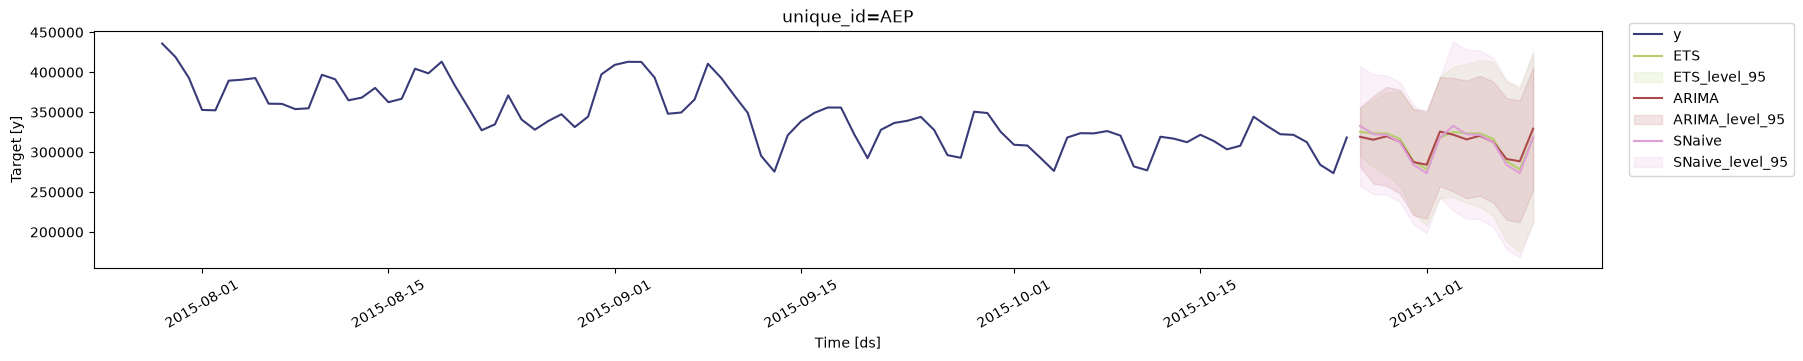

In [12]:
# Прогноз от конца train с аналитическими интервалами трёх моделей.
# StatsForecast сам умеет рисовать интервалы — не надо собирать fill_between руками.
sf.fit(train[['unique_id', 'ds', 'y']])
forecast_last = sf.predict(h=H, level=[95])

sf.plot(
    train[['unique_id', 'ds', 'y']],
    forecast_last,
    models=['ETS', 'ARIMA', 'SNaive'],
    level=[95],
    max_insample_length=90,
    engine='matplotlib',
)

## 2. Карта блока: допущения методов

Методы интервалов различаются по трём осям: какое распределение ошибок предполагается,
должна ли модель быть верной, и можно ли считать ошибки независимыми. Таблица — навигатор
по всему блоку: то, что мы делаем руками ниже, — это ровно то же, что библиотеки прячут
за красивыми именами (`NaiveVariance`, `EmpiricalPredictionIntervals`).

| Метод | Распределение ошибок | Модель должна быть верной | Ошибки независимы |
|---|---|---|---|
| Аналитические (ETS/ARIMA) | нормальное | да | да (i.i.d.) |
| `NaiveVariance` (ETNA) | нормальное | нет | нет |
| `EmpiricalPredictionIntervals` (ETNA) | любое | нет | нет |
| σ по горизонту | нормальное (по форме) | нет | нет |
| Эмпирические квантили остатков | любое | нет | нет |
| Бутстреп остатков | любое | да (иначе остатки не шум) | да |
| Блочный бутстреп / бэггинг рядов | любое | нет | нет (блоки) |
| Конформные интервалы | любое | нет | да (перестановочность) |
| Квантильная регрессия | любое | нет | нет |

Чем ниже по таблице, тем меньше предположений. Аналитика требует всего сразу; эмпирические
методы отказываются от нормальности и верной модели, но опираются на то, что прошлые ошибки
похожи на будущие. Формальную гарантию покрытия из всего списка дают только конформные интервалы.

## 3. Интервалы из ошибок на кросс-валидации

Вместо аналитической формулы берём остатки **бэктеста** — те, что модель уже видела
как будущее, — и переносим их распределение на новый прогноз. Три варианта:

1. **одна σ на все горизонты** — самый грубый: считается, что неопределённость не растёт;
2. **σ(h) по каждому горизонту** — учитывает рост, но интервал остаётся симметричным;
3. **эмпирические квантили по горизонтам** — не предполагает симметрии и нормальности.

Ключевое отличие от §1: остатки берём на **отложенных** окнах, а не in-sample. Остатки
на обучении соответствуют одношаговому прогнозу на уже виденных данных, поэтому σ по train
ничего не знает про рост ошибки с горизонтом.

Чтобы сравнение было честным, делим окна на две части: на первых **калибруем** (считаем σ
и квантили), на последних **оцениваем**. Иначе мы оценили бы метод на тех же данных,
по которым его настроили.

In [13]:
cutoffs = np.sort(backtest['cutoff'].unique())
split_cal = int(len(cutoffs) * 0.67)

calib = backtest[backtest['cutoff'].isin(cutoffs[:split_cal])]
evaluate = backtest[backtest['cutoff'].isin(cutoffs[split_cal:])].copy()

print(f"Калибровка: {calib['cutoff'].nunique()} окон, {len(calib)} точек")
print(f"Оценка:     {evaluate['cutoff'].nunique()} окон, {len(evaluate)} точек")

Калибровка: 80 окон, 1120 точек
Оценка:     40 окон, 560 точек


In [14]:
resid = calib['y'] - calib['ETS']

sigma_pooled = resid.std()
sigma_by_h = resid.groupby(calib['h']).std()
q_lo_by_h = resid.groupby(calib['h']).quantile(0.025)
q_hi_by_h = resid.groupby(calib['h']).quantile(0.975)

Z95 = 1.959963985

growth = pd.DataFrame({
    'sigma': sigma_by_h,
    'q025': q_lo_by_h,
    'q975': q_hi_by_h,
})
print(f"σ (одна на все горизонты): {sigma_pooled:,.0f}")
print(f"σ(h): h=1 {sigma_by_h.iloc[0]:,.0f} → h={H} {sigma_by_h.iloc[-1]:,.0f}, "
      f"рост {sigma_by_h.iloc[-1] / sigma_by_h.iloc[0]:.2f}×")
growth.round(0).T

σ (одна на все горизонты): 36,036
σ(h): h=1 16,285 → h=14 41,461, рост 2.55×


h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
sigma,16285.0,25143.0,30014.0,33009.0,34522.0,35655.0,36520.0,37649.0,39349.0,40998.0,41819.0,42348.0,42089.0,41461.0
q025,-31950.0,-44584.0,-48306.0,-46946.0,-57099.0,-68041.0,-77717.0,-74275.0,-81933.0,-82913.0,-83142.0,-86337.0,-76260.0,-71346.0
q975,27201.0,41633.0,64576.0,63979.0,58955.0,63710.0,68458.0,63656.0,63829.0,60804.0,63533.0,62285.0,71167.0,77516.0


Обратите внимание на асимметрию квантилей: на $h=1$ нижний квантиль по модулю больше верхнего
($-32$ тыс. против $+27$ тыс.): дни, когда факт сильно ниже прогноза, бывают чаще, чем
сильно выше. На $h=3$ картина обратная ($-48$ против $+65$ тыс.), а на $h=9$–$12$ снова тяжелее
нижний хвост. Симметричный интервал $\pm z\sigma$ этого не передаёт, а квантили передают.

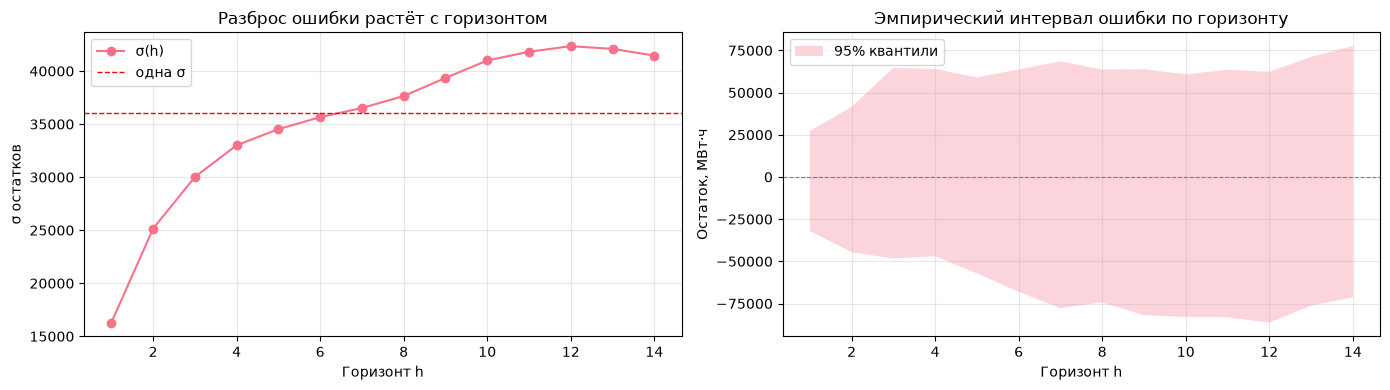

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(growth.index, growth['sigma'], 'o-', label='σ(h)')
axes[0].axhline(sigma_pooled, color='red', linestyle='--', linewidth=1, label='одна σ')
axes[0].set_xlabel('Горизонт h')
axes[0].set_ylabel('σ остатков')
axes[0].set_title('Разброс ошибки растёт с горизонтом')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].fill_between(growth.index, growth['q025'], growth['q975'], alpha=0.3, label='95% квантили')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_xlabel('Горизонт h')
axes[1].set_ylabel('Остаток, МВт·ч')
axes[1].set_title('Эмпирический интервал ошибки по горизонту')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Теперь применяем три варианта к окнам оценки. Чтобы прогнать их через тот же
`interval_metrics` и `plot_series`, кладём границы в колонки с привычными именами
`{имя}-lo-95` / `{имя}-hi-95` — так интервалы становятся «моделями» для utilsforecast.

In [16]:
def with_intervals(frame, name, lower, upper, point_col='ETS', level=95):
    """Копия бэктеста с интервалом под именем `name` — чтобы метрики и графики работали как обычно."""
    out = frame[['unique_id', 'ds', 'cutoff', 'y']].copy()
    out[name] = frame[point_col].values
    out[f'{name}-lo-{level}'] = np.asarray(lower)
    out[f'{name}-hi-{level}'] = np.asarray(upper)
    return out


variants = {
    'sigma_pooled': with_intervals(evaluate, 'sigma_pooled',
                                   evaluate['ETS'] - Z95 * sigma_pooled,
                                   evaluate['ETS'] + Z95 * sigma_pooled),
    'sigma_by_h': with_intervals(evaluate, 'sigma_by_h',
                                 evaluate['ETS'] - Z95 * evaluate['h'].map(sigma_by_h),
                                 evaluate['ETS'] + Z95 * evaluate['h'].map(sigma_by_h)),
    'quantiles': with_intervals(evaluate, 'quantiles',
                                evaluate['ETS'] + evaluate['h'].map(q_lo_by_h),
                                evaluate['ETS'] + evaluate['h'].map(q_hi_by_h)),
}

comparison = pd.concat([
    # аналитику пересчитываем на тех же окнах оценки — иначе сравнение нечестное
    interval_metrics(evaluate, ['ETS']).rename(index={'ETS': 'analytic'}),
    *[interval_metrics(frame, [name]) for name, frame in variants.items()],
])
comparison.round(3)

,coverage,coverage_sd,coverage_min,width,winkler,MAE,width/MAE
analytic,0.991,0.033,0.857,160559.981,162125.679,18762.602,8.557
sigma_pooled,0.973,0.092,0.500,141256.693,149760.717,18762.602,7.529
sigma_by_h,0.979,0.061,0.714,139118.280,145620.193,18762.602,7.415
quantiles,0.977,0.073,0.643,127296.528,138641.016,18762.602,6.785


**Результат.** Аналитика на окнах оценки перестраховывается (покрытие ≈0.99), а три
эмпирических варианта дают 0.97–0.98 — ближе к номиналу и при заметно меньшей ширине:
квантили уже аналитики примерно на 20%. Это и есть резкость: почти тот же уровень доверия
за более узкий интервал.

Одна σ на все горизонты при этом самая неровная (`coverage_min` = 0.5): она завышена
на коротких горизонтах и занижена на длинных — в среднем всё сходится, а по окнам нет.

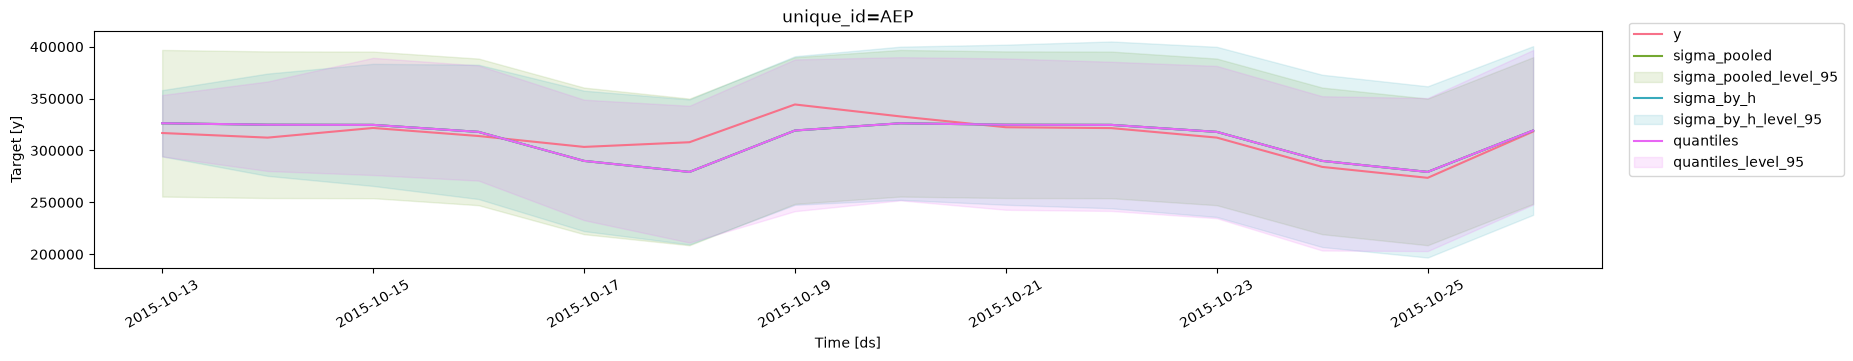

In [17]:
# Одно окно оценки — для наглядного сравнения всех интервалов на одних и тех же точках.
last_cutoff = evaluate['cutoff'].max()
window = {name: frame[frame['cutoff'] == last_cutoff] for name, frame in variants.items()}

plot_df = pd.concat([
    window['sigma_pooled'],
    window['sigma_by_h'][['sigma_by_h', 'sigma_by_h-lo-95', 'sigma_by_h-hi-95']],
    window['quantiles'][['quantiles', 'quantiles-lo-95', 'quantiles-hi-95']],
], axis=1)

plot_series(
    df=train[['unique_id', 'ds', 'y']].tail(90),
    forecasts_df=plot_df,
    models=['sigma_pooled', 'sigma_by_h', 'quantiles'],
    level=[95],
    engine='matplotlib',
    max_insample_length=0,
)

## 4. Бутстреп: откуда берётся разброс

До сих пор мы брали разброс ошибки «как есть». Бутстреп идёт дальше: генерирует много
правдоподобных будущих траекторий и берёт их эмпирические квантили. Источников
неопределённости два, и методы бутстрепа ловят их по-разному:

- **шум** — то, чего модель не объяснила (остатки);
- **оценка параметров** — то, что параметры найдены по конечной выборке и «пляшут».

Прежде чем писать код, зафиксируем, **чем различаются варианты бутстрепа** —
аккуратный разбор был в семинаре 4.3:

| Вариант | Что ресемплим | Предположения | Подводные камни |
|---|---|---|---|
| **i.i.d.** | отдельные точки | наблюдения независимы | ломает автокорреляцию; для рядов почти всегда занижает разброс |
| **MBB** (moving block) | блоки фиксированной длины $l$ | стационарность, слабая зависимость | крайние точки входят в меньше блоков; чувствителен к $l$ |
| **CBB** (circular block) | блоки по «кольцу» | те же | одна искусственная связь на стыке конца и начала |
| **Stationary bootstrap** | блоки случайной длины, средняя $1/p$ | те же | чуть менее устойчив, чем MBB при той же средней длине |
| **Residual bootstrap** | остатки модели | модель специфицирована верно | наследует все ошибки модели |

Все «правильные» варианты делают одно: **не разрывают связи**. Внутри блока порядок сохранён,
значит сохранены и локальные зависимости; рвутся они только на стыках блоков.

Ниже — численная проверка на AR(1) с известной истиной. Мы знаем точный разброс среднего,
поэтому видно, кто занижает, а кто нет.

In [18]:
def simulate_ar1(n_obs, phi=0.7, sigma=1.0, seed=0, burnin=200):
    """AR(1) из стационарного распределения; burn-in отбрасываем."""
    rng = np.random.default_rng(seed)
    total = n_obs + burnin
    x = np.zeros(total)
    x[0] = rng.normal(0, sigma / np.sqrt(1 - phi ** 2))
    eps = rng.normal(0, sigma, total)
    for t in range(1, total):
        x[t] = phi * x[t - 1] + eps[t]
    return x[burnin:]


def boot_iid(x, n_boot, seed=0):
    """Наивный бутстреп: тянем отдельные точки с возвращением."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    return x[idx].mean(axis=1)


def boot_mbb(x, block_length, n_boot, seed=0, circular=False):
    """Блочный бутстреп. circular=True — CBB: ряд замкнут в кольцо, все точки равноправны."""
    rng = np.random.default_rng(seed)
    n_obs = len(x)
    n_blocks = int(np.ceil(n_obs / block_length))
    if circular:
        pool = np.concatenate([x, x[:block_length]])
        starts = rng.integers(0, n_obs, size=(n_boot, n_blocks))
    else:
        pool = x
        starts = rng.integers(0, n_obs - block_length + 1, size=(n_boot, n_blocks))

    samples = np.empty((n_boot, n_blocks * block_length))
    for b in range(n_boot):
        samples[b] = np.concatenate([pool[s:s + block_length] for s in starts[b]])
    return samples[:, :n_obs].mean(axis=1)


def boot_stationary(x, mean_block, n_boot, seed=0):
    """Stationary bootstrap: длина блока геометрическая со средним `mean_block` (= 1/p)."""
    rng = np.random.default_rng(seed)
    n_obs = len(x)
    p = 1.0 / mean_block

    current = rng.integers(0, n_obs, size=n_boot)   # старт каждого «куска»
    acc = np.empty((n_boot, n_obs))
    acc[:, 0] = x[current]
    for t in range(1, n_obs):
        jump = rng.random(n_boot) < p               # с вероятностью p — новый кусок
        current = np.where(jump, rng.integers(0, n_obs, size=n_boot), (current + 1) % n_obs)
        acc[:, t] = x[current]
    return acc.mean(axis=1)


PHI, N_OBS, N_BOOT = 0.7, 500, 1000
ar1 = simulate_ar1(N_OBS, phi=PHI, sigma=1.0, seed=1)

# Истинный разброс среднего для AR(1): Var = gamma(0)*(1+phi)/(1-phi)/T
gamma0 = 1.0 / (1 - PHI ** 2)
sd_true = np.sqrt(gamma0 * (1 + PHI) / (1 - PHI) / N_OBS)

rows = {'i.i.d.': boot_iid(ar1, N_BOOT, seed=0)}
for length in (7, 14, 28, 56):
    rows[f'MBB, l={length}'] = boot_mbb(ar1, length, N_BOOT, seed=0)
    rows[f'CBB, l={length}'] = boot_mbb(ar1, length, N_BOOT, seed=0, circular=True)
for mean_len in (7, 14, 28, 56):
    rows[f'Stationary, L={mean_len}'] = boot_stationary(ar1, mean_len, N_BOOT, seed=0)

sd_table = pd.DataFrame({
    'SD(среднего)': {k: v.std() for k, v in rows.items()},
    'к истине': {k: v.std() / sd_true for k, v in rows.items()},
})
print(f"Истинное SD(среднего) для AR(1) с phi={PHI}: {sd_true:.4f}\n")
print(sd_table.round(3).to_string())

Истинное SD(среднего) для AR(1) с phi=0.7: 0.1491

                  SD(среднего)  к истине
i.i.d.                   0.062     0.416
MBB, l=7                 0.117     0.785
CBB, l=7                 0.120     0.807
MBB, l=14                0.140     0.938
CBB, l=14                0.139     0.931
MBB, l=28                0.164     1.098
CBB, l=28                0.159     1.068
MBB, l=56                0.161     1.078
CBB, l=56                0.163     1.091
Stationary, L=7          0.129     0.868
Stationary, L=14         0.146     0.982
Stationary, L=28         0.166     1.116
Stationary, L=56         0.188     1.262


**Что видно.**
- **i.i.d.** занижает разброс примерно в 2.4 раза: перемешав точки, мы уничтожили автокорреляцию,
  и ряд «выглядит» как белый шум, у которого среднее оценивается гораздо точнее.
- **MBB / CBB** с ростом длины блока подтягиваются к истине: $l=7$ даёт ~0.8, $l=14$ — ~0.94.
  Дальше начинается перелёт (~1.07–1.10 при $l=28$–$56$): блоков в выборке мало, и оценка
  разброса сама становится шумной. CBB почти не отличается от MBB — разница только в судьбе
  крайних точек.
- **Stationary bootstrap** при средней длине 14 ближе всех к истине (~0.98), но при длинных
  блоках перелетает сильнее всех (1.26 при $L=56$): к шуму выбора блоков добавляется шум
  их длины. Зато его выборки сами стационарны — это его теоретическое преимущество.

Практическое правило: длина блока — порядка длины значимой автокорреляции; для дневных данных
с недельной сезонностью разумно начинать с $l = 7$–$14$.

### 4.2. Бутстреп остатков: `simulate` в statsforecast

Residual bootstrap — это «прогони модель вперёд много раз, на каждом шаге подставляя
случайный остаток из обучения». В statsforecast это уже есть: у обученной модели метод
`simulate(h, n_paths, error_distribution=...)`. Сравним два режима:

- `'normal'` — шум из $\mathcal N(0, \hat\sigma^2)$, то есть то же, что аналитика, только методом Монте-Карло;
- `'bootstrap'` — шум ресемплится из настоящих остатков: тяжёлые хвосты и асимметрия сохраняются.

Остатки берутся по одному, независимо — это i.i.d.-бутстреп остатков. Он корректен, только
если модель сняла всю зависимость и остатки действительно похожи на шум.

In [19]:
N_PATHS = 1000
ets = AutoETS(season_length=7).fit(train['y'].values)

paths = {
    'sim_normal': ets.simulate(h=H, n_paths=N_PATHS, seed=0, error_distribution='normal'),
    'sim_bootstrap': ets.simulate(h=H, n_paths=N_PATHS, seed=0, error_distribution='bootstrap'),
}

future = test.head(H)[['unique_id', 'ds', 'y']].reset_index(drop=True)
sim_forecast = future[['unique_id', 'ds']].copy()
for name, p in paths.items():
    sim_forecast[name] = np.median(p, axis=0)
    sim_forecast[f'{name}-lo-95'] = np.quantile(p, 0.025, axis=0)
    sim_forecast[f'{name}-hi-95'] = np.quantile(p, 0.975, axis=0)

analytic_last = forecast_last[['ETS', 'ETS-lo-95', 'ETS-hi-95']].reset_index(drop=True)
sim_forecast = pd.concat([sim_forecast, analytic_last], axis=1)

widths = pd.DataFrame({
    name: (sim_forecast[f'{name}-hi-95'] - sim_forecast[f'{name}-lo-95']).values
    for name in ['ETS', 'sim_normal', 'sim_bootstrap']
}, index=pd.RangeIndex(1, H + 1, name='h'))
print("Ширина 95%-интервала по горизонтам:")
widths.iloc[[0, 6, 13]].round(0)

Ширина 95%-интервала по горизонтам:


,ETS,sim_normal,sim_bootstrap
h,,,
1,59649.0,60306.0,62926.0
7,151441.0,159106.0,152946.0
14,214994.0,211659.0,221025.0


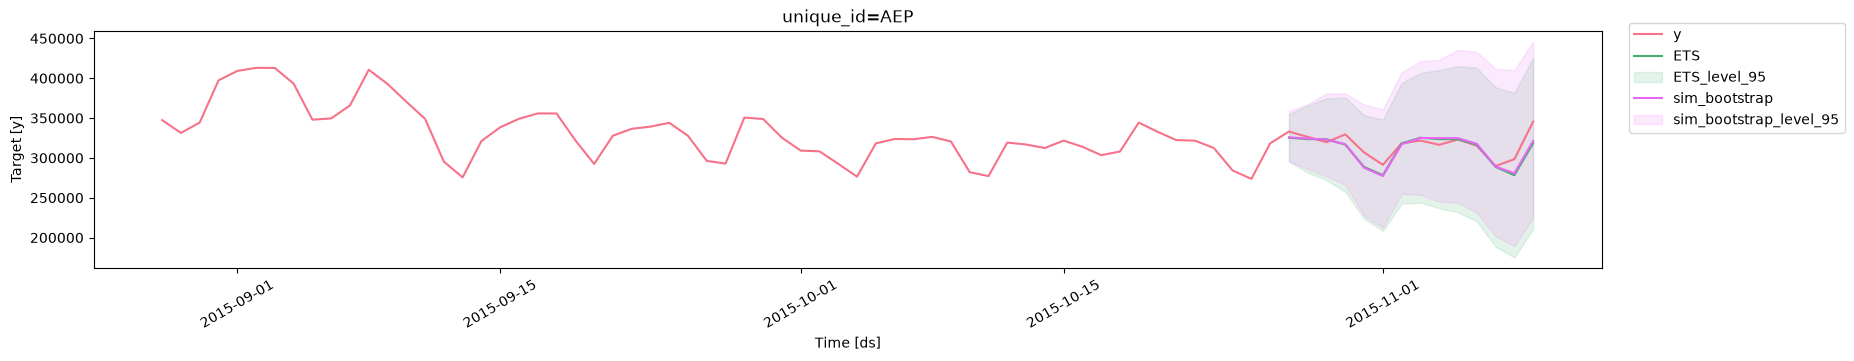

In [20]:
plot_series(
    df=pd.concat([train[['unique_id', 'ds', 'y']].tail(60), future]),
    forecasts_df=sim_forecast,
    models=['ETS', 'sim_bootstrap'],
    level=[95],
    engine='matplotlib',
)

`'normal'` практически совпадает с аналитикой — так и должно быть: это та же модель с тем же
предположением о нормальном шуме, просто посчитанная симуляцией. `'bootstrap'` даёт интервал
той же ширины, но без требования нормальности: если в остатках есть тяжёлый хвост,
он перенесётся в интервал.

**Чего бутстреп остатков не ловит:** неопределённость параметров (модель одна, обучена один раз)
и неверную спецификацию модели. Если ETS плохо описывает ряд, мы просто аккуратно
размножим неправильный шум.

### 4.3. Бэггинг рядов: блочный бутстреп + sktime

Чтобы поймать ещё и неопределённость параметров, ресемплим **сам ряд**: делаем $B$
«альтернативных историй», на каждой заново обучаем модель и усредняем прогнозы.
В sktime это `BaggingForecaster`.

**Важная деталь — что именно ресемплить.** Если применить MBB к сырому ряду, блоки из лета
и зимы перемешаются, и каждая бутстреп-история закончится на случайном уровне. Прогнозы
20 моделей стартуют откуда попало — на этих данных MAE такого бэггинга получается в ~6 раз
хуже ETS. Поэтому используют схему Бергмейра (`STLBootstrapTransformer`): ряд раскладывается
через STL на тренд, сезонность и остаток, блочным бутстрепом ресемплится **только остаток**,
а затем ряд собирается обратно. Уровень и сезонность сохраняются, «пляшет» только шум.

Обучаем на последних двух годах train: ARIMA переобучается на каждом из 20 рядов,
и на полной истории это заметно дольше без изменения смысла.

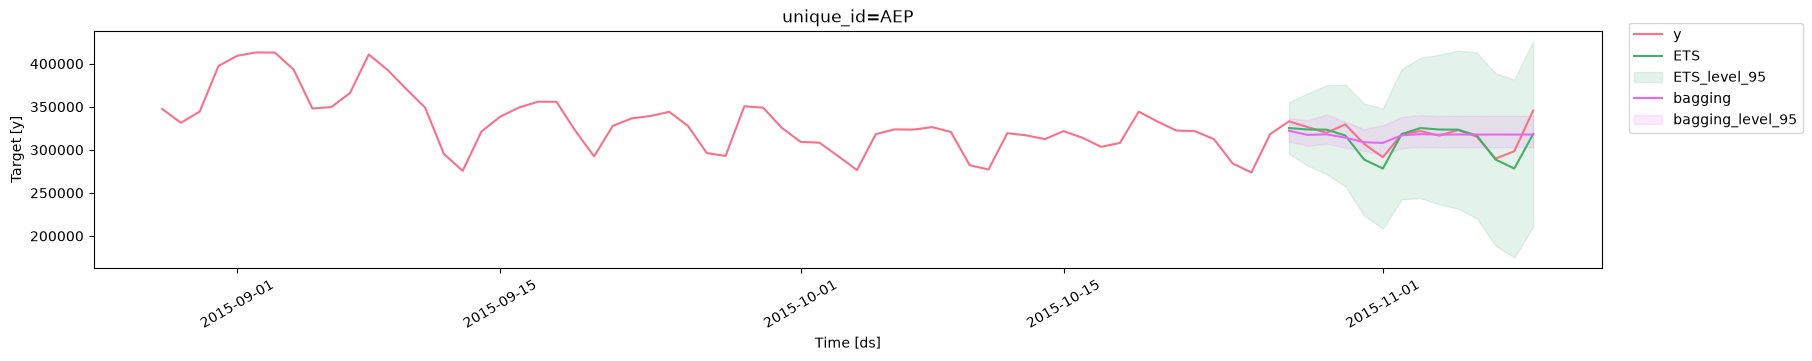

In [21]:
y_bag = train.set_index('ds')['y'].tail(730).asfreq('D')
fh = ForecastingHorizon(np.arange(1, H + 1), is_relative=True)

# sktime внутри сбрасывает фильтр FutureWarning, и глобальный filterwarnings('ignore') не спасает
# от спама про `remember_data`; record=True складывает предупреждения в список вместо печати.
with warnings.catch_warnings(record=True):
    bagging = BaggingForecaster(
        forecaster=ARIMA(order=(1, 1, 1), seasonal_order=(0, 0, 1, 7), suppress_warnings=True),
        bootstrap_transformer=STLBootstrapTransformer(sp=7, block_length=14, n_series=20, random_state=0),
        random_state=0,
    )
    bagging.fit(y_bag, fh=fh)
    bag_point = bagging.predict()
    bag_q = bagging.predict_quantiles(alpha=[0.025, 0.975])

sim_forecast['bagging'] = bag_point.values
sim_forecast['bagging-lo-95'] = bag_q.iloc[:, 0].values
sim_forecast['bagging-hi-95'] = bag_q.iloc[:, 1].values

plot_series(
    df=pd.concat([train[['unique_id', 'ds', 'y']].tail(60), future]),
    forecasts_df=sim_forecast,
    models=['ETS', 'bagging'],
    level=[95],
    engine='matplotlib',
)

In [22]:
methods = ['ETS', 'sim_normal', 'sim_bootstrap', 'bagging']
one_window = pd.DataFrame({
    m: {
        'coverage': ((future['y'] >= sim_forecast[f'{m}-lo-95']) & (future['y'] <= sim_forecast[f'{m}-hi-95'])).mean(),
        'width': (sim_forecast[f'{m}-hi-95'] - sim_forecast[f'{m}-lo-95']).mean(),
        'MAE': (future['y'] - sim_forecast[m]).abs().mean(),
    } for m in methods
}).T
one_window.round(3)

,coverage,width,MAE
ETS,1.000,151473.441,8515.018
sim_normal,1.000,153446.573,9422.590
sim_bootstrap,1.000,156872.623,8404.557
bagging,0.714,33829.318,10322.315


Это **одно окно из 14 точек** — по нему нельзя сказать, какой метод лучше откалиброван:
одна точка снаружи меняет покрытие на 0.07. Честное сравнение — как в §1 и §3, на десятках
окон бэктеста. Но порядок ширин видно и здесь.

Интервал бэггинга в разы уже остальных и не накрывает заметную часть точек. Причина —
в устройстве метода: квантили берутся по разбросу **прогнозов** 20 моделей, а не по разбросу
будущих значений. Это неопределённость модели (параметров), но не случайность самого ряда:
шум будущих дней в такой интервал не входит вовсе. Это не ошибка реализации — бэггинг
в первую очередь улучшает **точечный** прогноз, а как интервал для значений он занижен.

## 5. Итоги

1. **Агрегация может испортить последнюю точку.** Перед `resample` проверяйте полноту периода.
2. **Покрытие проверяем на многих окнах.** Один тест в 14 (а тем более в 1000) точек ничего
   не говорит о калибровке. `cross_validation` + `utilsforecast.losses.coverage` дают это в две строки.
3. **На этих данных аналитические интервалы слишком широкие**, а не узкие: покрытие ≈ 0.98,
   на дальних горизонтах — 1.00. Формула предполагает накопление шоков, а ряд возвращается к уровню.
4. **Эмпирические интервалы из бэктеста** (σ(h), квантили по горизонтам) дают то же покрытие
   при заметно меньшей ширине — и не требуют, чтобы модель была верной.
5. **Бутстреп** — это не один метод: i.i.d. для рядов занижает разброс; блочные варианты
   сохраняют зависимость; бутстреп остатков наследует ошибки модели; бэггинг ловит
   неопределённость параметров, но не шум, и ресемплить в нём надо остаток STL, а не сырой ряд.

Эмпирические квантили по ошибкам на отложенных окнах — это уже почти **конформные интервалы**.
В следующем ноутбуке формализуем эту идею и получим гарантию покрытия.